# Adult Income (>50K): Five-Model Classification

Predict whether annual income exceeds $50K from 1994 US census attributes (UCI Adult dataset).

Five classifiers are trained on the same split and compared on Accuracy, AUC, Precision, Recall, F1 and MCC. The trained pipelines are saved to `model/` for a Streamlit app, which scores uploaded test data without retraining.

**Setup:** Install project dependencies from the project root using `python -m pip install -r requirements.txt`. The notebook defines its configuration, data-cleaning and evaluation helper functions internally

**Dataset files:** Place `adult.data` and `adult.test` inside the `data/` directory before running the notebook.

In [13]:
%pip install seaborn

%pip install --upgrade threadpoolctl


import warnings

warnings.filterwarnings(
    "ignore",
    message=".*JsProxy.as_object_map.*",
    category=RuntimeWarning
)
import seaborn as sns

print(sns.__version__)

import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC


0.13.2


## Stage A: Import libraries and load data

In [2]:
import os
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix,
)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier


# ==========================================
# COMMON CONFIGURATION AND HELPER FUNCTIONS
# ==========================================

from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)

# Define the project folder
# In Jupyter, use the current working directory
ROOT = Path.cwd()

# Define file and folder locations
DATA_DIR = ROOT / "data"
MODEL_DIR = ROOT / "model"
TEST_CSV = ROOT / "test_data.csv"

# Dataset information
DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/"
TRAIN_FILE = "adult.data"
TEST_FILE = "adult.test"

# Target column
TARGET = "income"

POSITIVE_LABEL = ">50K"
NEGATIVE_LABEL = "<=50K"

# Numerical features
NUMERIC_FEATURES = [
    "age",
    "fnlwgt",
    "education_num",
    "capital_gain",
    "capital_loss",
    "hours_per_week"
]

# Categorical features
CATEGORICAL_FEATURES = [
    "workclass",
    "education",
    "marital_status",
    "occupation",
    "relationship",
    "race",
    "sex",
    "native_country"
]

# Combine all input features
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

# Original dataset column names
RAW_COLUMNS = [
    "age",
    "workclass",
    "fnlwgt",
    "education",
    "education_num",
    "marital_status",
    "occupation",
    "relationship",
    "race",
    "sex",
    "capital_gain",
    "capital_loss",
    "hours_per_week",
    "native_country",
    TARGET
]

# Model filenames
MODEL_FILES = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Naive Bayes": "naive_bayes.joblib",
    "SVM": "svm.joblib",
}

# Evaluation metrics
METRIC_NAMES = [
    "Accuracy",
    "AUC",
    "Precision",
    "Recall",
    "F1",
    "MCC"
]


# ==========================================
# FUNCTION 1: NORMALIZE DATASET LABELS
# ==========================================

def normalize_labels(df):

    # Create a copy to avoid modifying original data
    df = df.copy()

    # Remove unnecessary spaces
    for col in CATEGORICAL_FEATURES + [TARGET]:
        df[col] = df[col].astype(str).str.strip()

    # Remove trailing full stops from target labels
    df[TARGET] = df[TARGET].str.rstrip(".")

    # Replace missing categorical values represented by ?
    df[CATEGORICAL_FEATURES] = df[CATEGORICAL_FEATURES].replace(
        "?", "Unknown"
    )

    return df


# ==========================================
# FUNCTION 2: GET POSITIVE CLASS SCORES
# ==========================================

def positive_scores(model, X):

    # Use predicted probabilities if available
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]

    # Otherwise, use decision function
    return model.decision_function(X)


# ==========================================
# FUNCTION 3: EVALUATE MACHINE LEARNING MODEL
# ==========================================

def evaluate_model(model, X, y_true):

    # Predict output labels
    y_pred = model.predict(X)

    # Get scores for positive class
    y_score = positive_scores(model, X)

    # Calculate evaluation metrics
    return {
        "Accuracy": accuracy_score(y_true, y_pred),

        "AUC": roc_auc_score(y_true, y_score),

        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),

        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),

        "F1": f1_score(
            y_true, y_pred, zero_division=0
        ),

        "MCC": matthews_corrcoef(y_true, y_pred),
    }

RANDOM_STATE = 42
pd.set_option("display.width", 120)

The UCI files have no header row. `adult.test` starts with a comment line and its labels end with a period (`>50K.`), so both files are read with the same column names and cleaned by `normalize_labels` from `common.py`, which the app also uses.

In [3]:
train_raw = pd.read_csv(
    "data/adult.data",
    header=None,
    names=RAW_COLUMNS,
    skipinitialspace=True,
)
test_raw = pd.read_csv(
    "data/adult.test",
    header=None,
    names=RAW_COLUMNS,
    skipinitialspace=True,
    skiprows=1,
)

print("Train shape:", train_raw.shape)
print("Test shape: ", test_raw.shape)
train_raw.head()

Train shape: (32561, 15)
Test shape:  (16281, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


## Stage B: Data understanding

In [4]:
train_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             32561 non-null  int64
 1   workclass       32561 non-null  str  
 2   fnlwgt          32561 non-null  int64
 3   education       32561 non-null  str  
 4   education_num   32561 non-null  int64
 5   marital_status  32561 non-null  str  
 6   occupation      32561 non-null  str  
 7   relationship    32561 non-null  str  
 8   race            32561 non-null  str  
 9   sex             32561 non-null  str  
 10  capital_gain    32561 non-null  int64
 11  capital_loss    32561 non-null  int64
 12  hours_per_week  32561 non-null  int64
 13  native_country  32561 non-null  str  
 14  income          32561 non-null  str  
dtypes: int64(6), str(9)
memory usage: 2.6 MB


The training data has 32,561 rows and 15 columns: 6 integer columns and 9 object columns. The PDF reports approximately 2.6 MB of memory usage.

In [5]:
train_raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,32561.0,38.58,13.64,17.0,28.0,37.0,48.0,90.0
fnlwgt,32561.0,189778.37,105549.98,12285.0,117827.0,178356.0,237051.0,1484705.0
education_num,32561.0,10.08,2.57,1.0,9.0,10.0,12.0,16.0
capital_gain,32561.0,1077.65,7385.29,0.0,0.0,0.0,0.0,99999.0
capital_loss,32561.0,87.30,402.96,0.0,0.0,0.0,0.0,4356.0
hours_per_week,32561.0,40.44,12.35,1.0,40.0,40.0,45.0,99.0


In [6]:
print("Null values per column:")
print(train_raw.isnull().sum().to_string())

qmarks = (train_raw[CATEGORICAL_FEATURES] == "?").sum()
print('\n"?" placeholders per categorical column:')
print(qmarks[qmarks > 0].to_string())

Null values per column:
age               0
workclass         0
fnlwgt            0
education         0
education_num     0
marital_status    0
occupation        0
relationship      0
race              0
sex               0
capital_gain      0
capital_loss      0
hours_per_week    0
native_country    0
income            0

"?" placeholders per categorical column:
workclass         1836
occupation        1843
native_country     583


In [7]:
print("Duplicate rows in train:", train_raw.duplicated().sum())
print("Duplicate rows in test: ", test_raw.duplicated().sum())

train = normalize_labels(train_raw)
test = normalize_labels(test_raw)

for name, df in [("Train", train), ("Test", test)]:
    counts = df[TARGET].value_counts()
    summary = pd.DataFrame({
        "count": counts,
        "percent": (counts / len(df) * 100).round(2),
    })
    print(f"{name} target distribution:")
    print(summary.to_string(), end="\n\n")

Duplicate rows in train: 24
Duplicate rows in test:  5
Train target distribution:
        count  percent
income                
<=50K   24720    75.92
>50K     7841    24.08

Test target distribution:
        count  percent
income                
<=50K   12435    76.38
>50K     3846    23.62



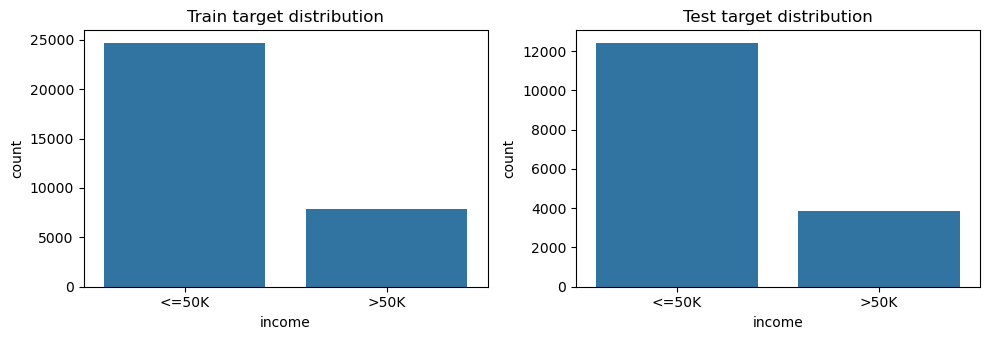

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, (name, df) in zip(axes, [("Train", train), ("Test", test)]):
    sns.countplot(x=TARGET, data=df, order=[NEGATIVE_LABEL, POSITIVE_LABEL], ax=ax)
    ax.set_title(f"{name} target distribution")
plt.tight_layout()
plt.show()

In [9]:
print("Numerical predictors :", NUMERIC_FEATURES)
print("Categorical predictors:", CATEGORICAL_FEATURES)
print("Total predictors      :", len(FEATURES))

Numerical predictors : ['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']
Categorical predictors: ['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country']
Total predictors      : 14


### Findings

- There are 14 predictors: 6 numerical and 8 categorical.
- `workclass`, `occupation` and `native_country` contain `?` placeholders. They are kept as an explicit Unknown category rather than dropped, because missingness may itself carry signal and dropping would remove rows from both splits.
- The target is imbalanced (about 24% `>50K`), so Accuracy alone is misleading. A model that always predicts `<=50K` would score about 76%. AUC, F1 and MCC are more informative here.
- The few duplicate rows are kept: with no record ID, identical census answers from different people are plausible.

## Stage C: Preprocessing without data leakage

The official UCI split is used instead of a new random split: `adult.data` (32,561 rows) for training and `adult.test` (16,281 rows) as the held-out test set. The scaler and encoder sit inside each pipeline, so they are fitted on training data only and are saved with the model. This lets the Streamlit app accept raw feature columns.

In [10]:
X_train = train[FEATURES]
y_train = (train[TARGET] == POSITIVE_LABEL).astype(int)
X_test = test[FEATURES]
y_test = (test[TARGET] == POSITIVE_LABEL).astype(int)

print("X_train:", X_train.shape, " X_test:", X_test.shape)
print("Positive rate - train: %.4f, test: %.4f" % (y_train.mean(), y_test.mean()))

X_train: (32561, 14)  X_test: (16281, 14)
Positive rate - train: 0.2408, test: 0.2362


In [11]:
def make_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), NUMERIC_FEATURES),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            CATEGORICAL_FEATURES,
        ),
    ])

encoded_width = make_preprocessor().fit(X_train).transform(X_train.head(1)).shape[1]
print("Columns after scaling and one-hot encoding:", encoded_width)

Columns after scaling and one-hot encoding: 108


## Stage D: Train the five required models

Every model uses the same training data and the same preprocessing. The SVM is implemented with `LinearSVC` (a linear support vector classifier). It does not expose `predict_proba`; its AUC is therefore computed from `decision_function` scores.

In [14]:
classifiers = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Naive Bayes": GaussianNB(),
    "SVM": LinearSVC(
        C=1.0,
        max_iter=3000,
        random_state=RANDOM_STATE
    ),}

pipelines = {}
for name, clf in classifiers.items():
    start = time.perf_counter()
    pipe = Pipeline([("preprocess", make_preprocessor()), ("model", clf)])
    pipe.fit(X_train, y_train)
    pipelines[name] = pipe
    print(f"{name:<20} trained in {time.perf_counter() - start:6.1f}s")

Logistic Regression  trained in    3.0s
Decision Tree        trained in    2.0s
KNN                  trained in    0.3s
Naive Bayes          trained in    0.4s
SVM                  trained in    2.5s


## Stage E: Evaluate all models consistently

`evaluate_model` in `common.py` is the single metric definition shared by this notebook and the app. It uses predicted probabilities for AUC where available and decision scores otherwise.

| Metric | Interpretation |
|---|---|
| Accuracy | Share of all predictions that are correct. Misleading under class imbalance. |
| AUC | Ranking quality across all thresholds, computed from scores rather than hard labels. |
| Precision | Of the people predicted `>50K`, the share who really are. |
| Recall | Of the people who really are `>50K`, the share the model finds. |
| F1 | Harmonic mean of precision and recall. |
| MCC | Correlation between predictions and truth using all four confusion-matrix cells. |

In [15]:
results = pd.DataFrame(
    {name: evaluate_model(pipe, X_test, y_test) for name, pipe in pipelines.items()}
).T[METRIC_NAMES]

results.index.name = "ML Model Name"
results.round(4)

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.8530,0.9055,0.7306,0.5985,0.6580,0.5701
Decision Tree,0.8082,0.7405,0.5909,0.6121,0.6013,0.4752
KNN,0.8332,0.8579,0.6622,0.5998,0.6295,0.5232
Naive Bayes,0.5532,0.7639,0.3389,0.9376,0.4979,0.3320
SVM,0.8540,0.9048,0.7387,0.5910,0.6567,0.5711


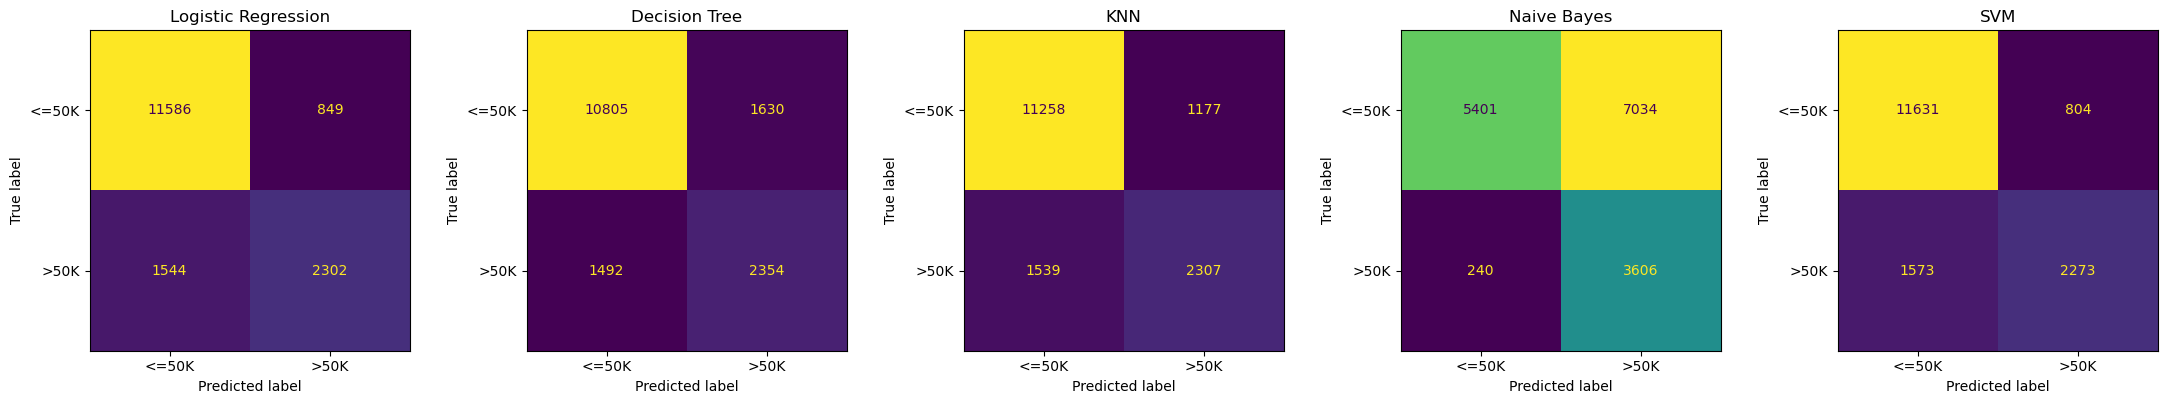

In [16]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, (name, pipe) in zip(axes, pipelines.items()):
    cm = confusion_matrix(y_test, pipe.predict(X_test), labels=[0, 1])
    ConfusionMatrixDisplay(
        cm,
        display_labels=[NEGATIVE_LABEL, POSITIVE_LABEL],
    ).plot(ax=ax, colorbar=False, values_format="d")
    ax.set_title(name)
plt.tight_layout()
plt.show()

In [17]:
for name, pipe in pipelines.items():
    print(f"===== {name} =====")
    print(
        classification_report(
            y_test,
            pipe.predict(X_test),
            target_names=[NEGATIVE_LABEL, POSITIVE_LABEL],
            digits=4,
        )
    )

===== Logistic Regression =====
              precision    recall  f1-score   support

       <=50K     0.8824    0.9317    0.9064     12435
        >50K     0.7306    0.5985    0.6580      3846

    accuracy                         0.8530     16281
   macro avg     0.8065    0.7651    0.7822     16281
weighted avg     0.8465    0.8530    0.8477     16281

===== Decision Tree =====
              precision    recall  f1-score   support

       <=50K     0.8787    0.8689    0.8738     12435
        >50K     0.5909    0.6121    0.6013      3846

    accuracy                         0.8082     16281
   macro avg     0.7348    0.7405    0.7375     16281
weighted avg     0.8107    0.8082    0.8094     16281

===== KNN =====
              precision    recall  f1-score   support

       <=50K     0.8797    0.9053    0.8924     12435
        >50K     0.6622    0.5998    0.6295      3846

    accuracy                         0.8332     16281
   macro avg     0.7710    0.7526    0.7609     16281


## Stage F: Final comparison and observations

In [18]:
leaders = pd.DataFrame({
    "Best model": results.idxmax(),
    "Score": results.max().round(4),
})
leaders.index.name = "Metric"
leaders

,Best model,Score
Metric,,
Accuracy,SVM,0.8540
AUC,Logistic Regression,0.9055
Precision,SVM,0.7387
Recall,Naive Bayes,0.9376
F1,Logistic Regression,0.6580
MCC,SVM,0.5711


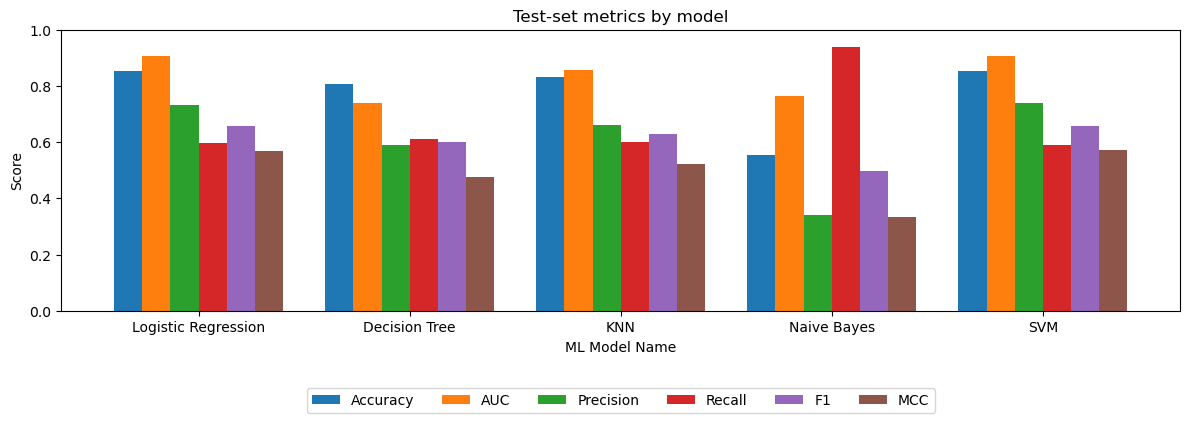

In [19]:
ax = results.plot(kind="bar", figsize=(12, 4.5), width=0.8)
ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title("Test-set metrics by model")
ax.legend(ncol=6, loc="upper center", bbox_to_anchor=(0.5, -0.25))
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Observations

Test set: 16,281 rows; majority-class baseline accuracy: 0.7638.

- **Logistic Regression:** Highest AUC (0.9055) and second-best MCC (0.5701). Precision (0.7306) is higher than recall (0.5985), indicating that the model is relatively conservative when predicting `>50K`. It provides strong overall performance and comes close to the best-performing model.

- **Decision Tree:** Lowest AUC (0.7405) and second-lowest accuracy (0.8082). Its precision (0.5909) and recall (0.6121) are relatively close, but both are modest. The tree uses default settings without pruning; the reason for its weaker ranking performance was not investigated.

- **KNN:** Middle of the group, with accuracy 0.8332, AUC 0.8579 and MCC 0.5232. Precision (0.6622) and recall (0.5998) are lower than those of the top-performing models. It is also the largest saved model (28.4 MB) because it stores the training data.

- **Naive Bayes:** Highest recall (0.9376) but lowest precision (0.3389). It identifies most actual `>50K` cases, but many of its positive predictions are incorrect. Its accuracy (0.5532) is far below the majority-class baseline (0.7638), making it unsuitable as a general-purpose classifier in its current configuration.

- **Support Vector Machine (SVM):** Best accuracy (0.8540), precision (0.7387) and MCC (0.5711). Its F1 score (0.6567) is slightly below Logistic Regression (0.6580), while its AUC (0.9048) is just below Logistic Regression (0.9055). Its recall (0.5910) is the lowest among the five models.

**Overall winner:** SVM achieves the highest accuracy, precision and MCC, while Logistic Regression achieves the highest AUC and F1 score. SVM has the strongest MCC, making it a good overall choice when considering balanced classification performance under class imbalance. Logistic Regression is a close alternative, with slightly better AUC and F1. The performance difference between these two models has not been tested for statistical significance.

**Trade-off:** If identifying as many high earners as possible is important, Naive Bayes offers the highest recall, although at the cost of very low precision. Alternatively, lowering the decision threshold of Logistic Regression or SVM may improve recall. If avoiding false positive predictions is more important, SVM provides the highest precision.

## Stage G: Save the trained pipelines and test data

Run this only after all training cells have executed in the current session. Each saved file is a full pipeline, preprocessing included.

In [20]:
os.makedirs("model", exist_ok=True)

for name, pipe in pipelines.items():
    path = os.path.join("model", MODEL_FILES[name])
    joblib.dump(pipe, path)
    print(
        f"Saved {name:<20} -> {path} "
        f"({os.path.getsize(path) / 1e6:.2f} MB)"
    )

test[RAW_COLUMNS].to_csv("test_data.csv", index=False)
print(
    "Saved test_data.csv with",
    len(test),
    "rows and",
    len(RAW_COLUMNS),
    "columns (target included)",
)

Saved Logistic Regression  -> model/logistic_regression.joblib (0.01 MB)
Saved Decision Tree        -> model/decision_tree.joblib (0.68 MB)
Saved KNN                  -> model/knn.joblib (28.27 MB)
Saved Naive Bayes          -> model/naive_bayes.joblib (0.01 MB)
Saved SVM                  -> model/svm.joblib (0.01 MB)
Saved test_data.csv with 16281 rows and 15 columns (target included)


## Stage H: Verify the saved models load without retraining

Reload every pipeline from disk, score the exported `test_data.csv`, and confirm the metrics are identical to the in-memory results above.

In [21]:
reloaded_test = normalize_labels(pd.read_csv("test_data.csv"))
X_check = reloaded_test[FEATURES]
y_check = (reloaded_test[TARGET] == POSITIVE_LABEL).astype(int)

reloaded = pd.DataFrame({
    name: evaluate_model(joblib.load(os.path.join("model", filename)), X_check, y_check)
    for name, filename in MODEL_FILES.items()
}).T[METRIC_NAMES]

max_diff = (reloaded - results).abs().to_numpy().max()
print("Largest metric difference after reload:", max_diff)
assert max_diff < 1e-12, "Reloaded models do not reproduce the notebook metrics"

print(
    "Sample predictions from reloaded SVM:",
    joblib.load("model/svm.joblib").predict(X_check.head(5)),
)

Largest metric difference after reload: 0.0
Sample predictions from reloaded SVM: [0 0 0 1 0]
